In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.basemap import Basemap

In [103]:
folder_n = "unified-sea-ice-thickness-cdr-1947-2017/"
df_l = []
for fn in os.listdir(folder_n):
    readstring = []
    if ('summaries' in fn):
        with open(folder_n+fn, 'rb') as file:
            readstring = file.readlines()
        data = [[el.decode() for el in line.replace(b"\n", b"").split(b" ") if el != b''] for line in readstring]
        data = pd.DataFrame(data[1:], columns=data[0])
        types = {data.columns[i]:(float if (i > 1) else str) for i in range(len(data.columns))}
        data = data.astype(types)
        ## stringent case filter
        #data = data[data['Year'] == 2009]
        #data = data[data['MinDay'] > 110]
        #data = data[data['MaxDay'] < 130]
        ## generous case
        data = data[data['MinDay'] > 90]
        data = data[data['MaxDay'] < 150]
        df_l.append(data)
comcol = []
for df in df_l:
    if "Avg_draft" in df.columns:
        df['Avg_thkns'] = df['Avg_draft'].astype(float) * 1.1  # (very) rough conversion
df_l = [df for df in df_l if ("Avg_thkns" in df.columns)]
for df in df_l:
    for coln in df.columns:
        if (coln not in comcol):
            comcol.append(coln)
for df in df_l:
    for coln in comcol:
        if (coln not in df.columns):
            comcol.remove(coln)
df_l = [df[comcol] for df in df_l]

In [120]:
data = pd.concat(df_l)
data.index = np.arange(len(data))
data

,Source,Index,Year,Yday,MinDay,MaxDay,Month,Lat,Lon,MinLat,MaxLat,MinLon,MaxLon,Nsamps,Avg_thkns
0,AIR-EM,10010018.0,2003.0,91.0,91.0,91.0,4.0,80.24,12.82,80.08,80.40,12.82,12.83,10360.0,1.200
1,AIR-EM,10010019.0,2003.0,91.0,91.0,91.0,4.0,80.21,11.54,80.15,80.26,10.87,12.25,9111.0,1.350
2,AIR-EM,10010020.0,2003.0,94.0,94.0,94.0,4.0,81.62,10.58,81.59,81.64,10.19,11.08,5271.0,1.600
3,AIR-EM,10010021.0,2003.0,97.5,95.0,100.0,4.0,81.59,9.01,81.30,81.82,7.41,9.57,61559.0,2.370
4,AIR-EM,10010022.0,2003.0,100.0,100.0,100.0,4.0,81.11,9.29,80.92,81.30,9.01,9.54,24126.0,2.300
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20424,USSUB-DG,6320996.0,1999.0,132.0,132.0,132.0,5.0,84.32,10.45,84.00,84.65,10.16,10.75,72691.0,3.421
20425,USSUB-DG,6320997.0,1999.0,133.0,133.0,133.0,5.0,82.89,12.84,82.65,83.12,10.62,15.06,268653.0,3.223
20426,USSUB-DG,6320998.0,1999.0,133.0,133.0,133.0,5.0,82.30,10.33,82.10,82.53,9.02,11.65,60743.0,2.904
20427,USSUB-DG,6320999.0,1999.0,133.0,133.0,133.0,5.0,81.86,7.74,81.51,82.10,7.32,8.17,67678.0,2.486


In [1]:
#plt.scatter(data["Lon"].values, data["Lat"].values)
#plt.scatter(data["Lon"].values, data["Lat"].values, c=data['Avg_thkns'].values, s=50*np.exp(-np.abs(2009 - data["Year"])**2))
#plt.colorbar()

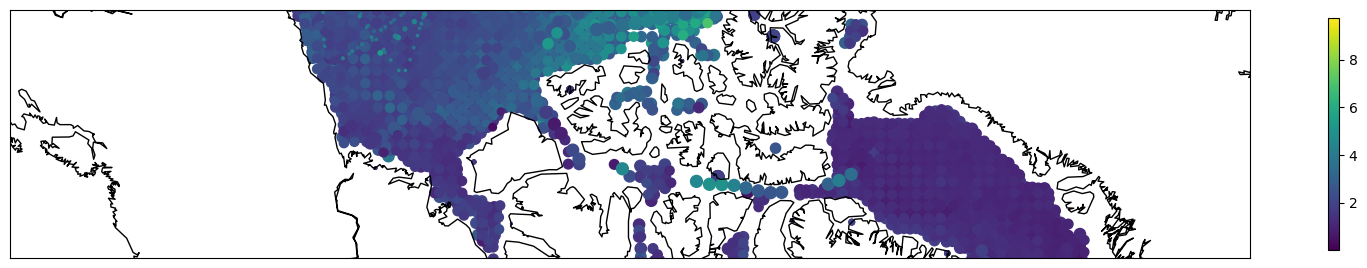

In [145]:
import numpy as np

fig = plt.figure(figsize = (20,20))

#m = Basemap( llcrnrx=-3000000, llcrnry=-3000000, urcrnrx=3000000, urcrnry=3000000, 
#             lon_0 = -90, lat_0 = 90, projection="ortho", resolution='c')
m = Basemap( llcrnrx=-3000000, llcrnry=-2000000, urcrnrx=2000000, urcrnry=-1000000, 
             lon_0 = -90, lat_0 = 90, projection="ortho", resolution='l')
m.drawcoastlines()
#m.drawmapboundary(fill_color='aqua') 
#m.fillcontinents(color='coral',lake_color='aqua')
#parallels = np.arange(0.,90,30.)
#m.drawparallels(parallels,labels=[1,0,0,1])
#meridians = np.arange(10.,360.,30.)
#m.drawmeridians(meridians,labels=[1,0,0,1])

#m.bluemarble()
#m.scatter(data["Lon"].values, data["Lat"].values)
#  day 120 of 2009 : April 30, 2009
sizes = np.exp(-np.abs(0.1*(2009 + 120/365.25 - data["Year"] - data["Yday"]/365)))
sizes /= np.max(sizes)
m.scatter(data["Lon"].values, data["Lat"].values, latlon=True, c=data['Avg_thkns'].values, s=80*sizes)
plt.colorbar(shrink=0.15)
plt.show()